<a href="https://colab.research.google.com/github/ruqayaahabib/Advanced-AI-Labs/blob/main/Week-04/Ruqaya_Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

1. Load the dataset from the UCI public URL.

In [ ]:
column_names = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# Treat '?' as missing values
df = pd.read_csv(
    url,
    names=column_names,
    na_values="?",
    skipinitialspace=True
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


2. Display the first 10 rows, shape, column names, data types, missing values, and target distribution.

In [ ]:
print("First 10 rows:")
display(df.head(10))

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["income"].value_counts())

First 10 rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


Dataset shape: (32561, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']

Data types:
age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object

Missing values:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income         

3. Convert the target income into a binary variable.

In [ ]:
# 0 = Income <=50K, 1 = Income >50K
df["income_binary"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

print("Binary target distribution:")
print(df["income_binary"].value_counts())

display(df[["income", "income_binary"]].head(10))

Binary target distribution:
income_binary
0    24720
1     7841
Name: count, dtype: int64


,income,income_binary
0,<=50K,0
1,<=50K,0
2,<=50K,0
3,<=50K,0
4,<=50K,0
5,<=50K,0
6,<=50K,0
7,>50K,1
8,>50K,1
9,>50K,1


4. Separate numerical and categorical features.

In [ ]:
# Separate input features (X) and target (y)
X = df.drop(columns=["income", "income_binary"])
y = df["income_binary"]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numeric_features))
print("Total categorical features:", len(categorical_features))


Numerical features:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical features:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Total numerical features: 6
Total categorical features: 8


5. Split the data into training and testing sets using stratification.

In [ ]:
# Stratification preserves the income class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set shape: (24420, 14)
Testing set shape: (8141, 14)

Training target distribution:
income_binary
0    0.759173
1    0.240827
Name: proportion, dtype: float64

Testing target distribution:
income_binary
0    0.759243
1    0.240757
Name: proportion, dtype: float64


6. Build a preprocessing pipeline using:


*   median imputation and standard scaling for numerical features
*   most-frequent imputation and one-hot encoding for categorical features



In [ ]:
# Fill missing numerical values using the median and scale them
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Fill missing categorical values and convert categories into numbers
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data to prevent data leakage
X_train_processed = preprocess.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

# Display a sample of the transformed features
processed_df = pd.DataFrame(
    X_train_processed[:5].toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed[:5],
    columns=preprocess.get_feature_names_out()
)

display(processed_df.iloc[:, :15].round(3))

Original training shape: (24420, 14)
Processed training shape: (24420, 105)


,num__age,num__fnlwgt,num__education_num,num__capital_gain,num__capital_loss,num__hours_per_week,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Never-worked,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_Without-pay,cat__education_10th
0,-0.774,0.401,-0.030,-0.146,-0.216,-0.037,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,-0.260,1.373,0.744,-0.146,-0.216,1.576,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-1.068,-0.475,-0.030,-0.146,-0.216,-0.037,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.180,1.207,-0.030,-0.146,-0.216,0.608,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-0.848,-0.532,1.517,-0.146,-0.216,-0.037,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


7. Train at least four classifiers:



*   7.1: Logistic Regression



In [ ]:
log_reg_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000))
])

log_reg_model.fit(X_train, y_train)

print("Training Accuracy:", round(log_reg_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(log_reg_model.score(X_test, y_test), 4))

Training Accuracy: 0.8511
Testing Accuracy: 0.8547




*   7.2 K-Nearest Neighbors (KNN)



In [ ]:
knn_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("classifier", KNeighborsClassifier(n_neighbors=7))
])

knn_model.fit(X_train, y_train)

print("Training Accuracy:", round(knn_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(knn_model.score(X_test, y_test), 4))

Training Accuracy: 0.8719
Testing Accuracy: 0.8415




*   7.3 Decision Tree



In [ ]:
# Limit the depth to reduce overfitting
tree_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Training Accuracy:", round(tree_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(tree_model.score(X_test, y_test), 4))

Training Accuracy: 0.8469
Testing Accuracy: 0.8482




*   7.4 Random Forest



In [ ]:
# Random Forest combines multiple decision trees
rf_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Training Accuracy:", round(rf_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(rf_model.score(X_test, y_test), 4))

Training Accuracy: 0.8649
Testing Accuracy: 0.859


8. Evaluate each model using:

In [ ]:
models = {
    "Logistic Regression": log_reg_model,
    "KNN": knn_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate the five required evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

# Rank models using F1-score
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8547,0.7373,0.6158,0.6711,0.9072
1,Random Forest,0.8590,0.7938,0.5597,0.6565,0.9130
2,KNN,0.8415,0.6882,0.6250,0.6551,0.8798
3,Decision Tree,0.8482,0.7798,0.5148,0.6202,0.8828


9. Display a confusion matrix for the best model.

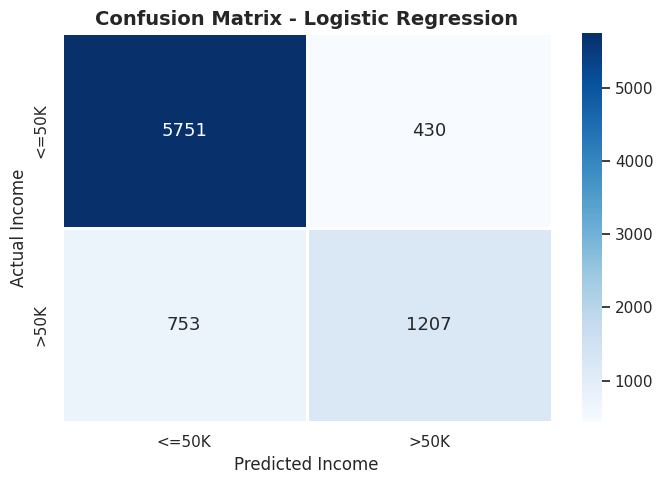

Best Model: Logistic Regression
F1-score: 0.6711

Confusion Matrix:
[[5751  430]
 [ 753 1207]]


In [ ]:
# Select the best individual model based on F1-score
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    xticklabels=["<=50K", ">50K"],
    yticklabels=["<=50K", ">50K"],
    annot_kws={"size": 13}
)

plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.tight_layout()
plt.show()

print("Best Model:", best_model_name)
print("F1-score:", round(results_df.iloc[0]["F1-score"], 4))
print("\nConfusion Matrix:")
print(cm)

10. Plot an ROC curve for at least two models.

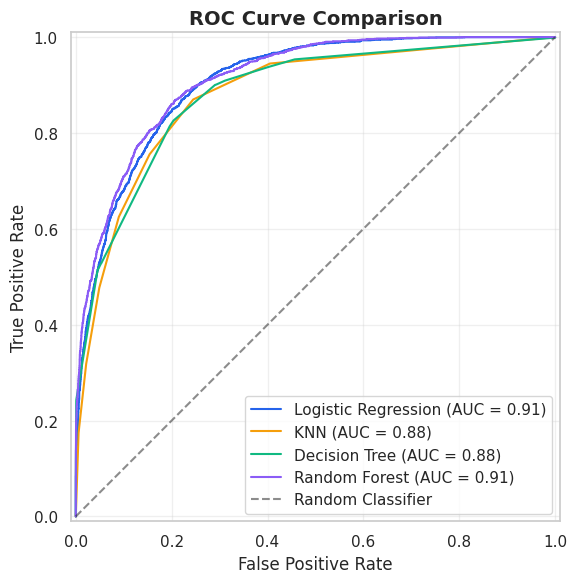

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

colors = ["#2563EB", "#F59E0B", "#10B981", "#8B5CF6"]

for (name, model), color in zip(models.items(), colors):
    y_prob = model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        color=color,
        ax=ax
    )

# Diagonal line represents random classification
ax.plot(
    [0, 1], [0, 1],
    "k--",
    alpha=0.5,
    label="Random Classifier"
)

plt.title("ROC Curve Comparison", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

11. Create a soft voting ensemble and compare it with the individual models.



*   11.1 Train the Soft Voting Ensemble



In [ ]:
# Soft voting averages the predicted probabilities of classifiers
voting_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("classifier", VotingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=1000)),
            ("dt", DecisionTreeClassifier(
                max_depth=5,
                random_state=42
            )),
            ("rf", RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                random_state=42,
                n_jobs=-1
            ))
        ],
        voting="soft"
    ))
])

voting_model.fit(X_train, y_train)

print("Training Accuracy:", round(voting_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(voting_model.score(X_test, y_test), 4))

Training Accuracy: 0.8571
Testing Accuracy: 0.8555




*   11.2 Evaluate and Compare All Models



In [ ]:
y_pred_vote = voting_model.predict(X_test)
y_prob_vote = voting_model.predict_proba(X_test)[:, 1]

voting_results = pd.DataFrame([{
    "Model": "Soft Voting Ensemble",
    "Accuracy": accuracy_score(y_test, y_pred_vote),
    "Precision": precision_score(y_test, y_pred_vote),
    "Recall": recall_score(y_test, y_pred_vote),
    "F1-score": f1_score(y_test, y_pred_vote),
    "ROC-AUC": roc_auc_score(y_test, y_prob_vote)
}])

# Add ensemble results to the individual model comparison
final_results = pd.concat(
    [results_df, voting_results],
    ignore_index=True
)

final_results = final_results.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8547,0.7373,0.6158,0.6711,0.9072
1,Random Forest,0.8590,0.7938,0.5597,0.6565,0.9130
2,KNN,0.8415,0.6882,0.6250,0.6551,0.8798
3,Soft Voting Ensemble,0.8555,0.7792,0.5582,0.6504,0.9112
4,Decision Tree,0.8482,0.7798,0.5148,0.6202,0.8828



*   11.3 Visualize the Final Model Comparison



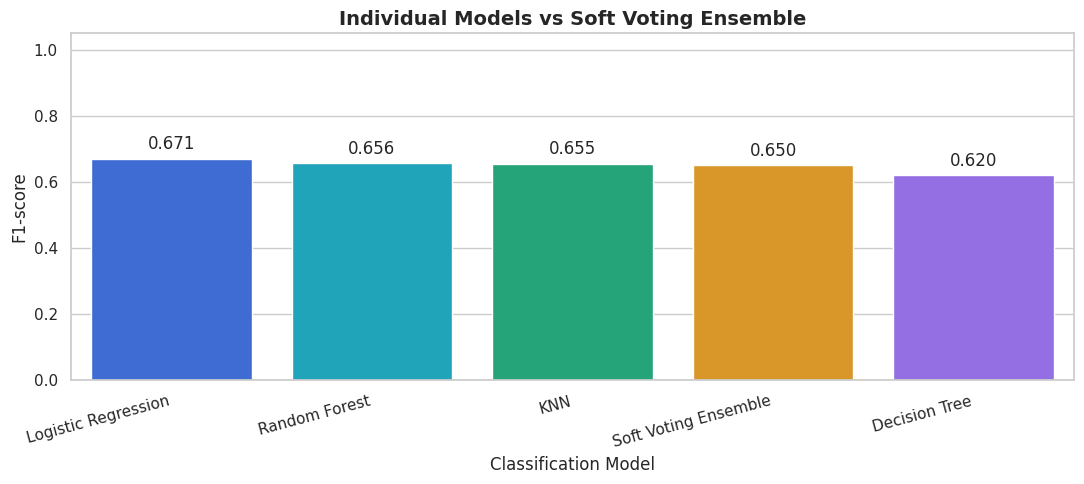

In [ ]:
plt.figure(figsize=(11, 5))

# Highlight the ensemble model using orange
colors = {
    "Logistic Regression": "#2563EB",
    "KNN": "#10B981",
    "Decision Tree": "#8B5CF6",
    "Random Forest": "#06B6D4",
    "Soft Voting Ensemble": "#F59E0B"
}

ax = sns.barplot(
    data=final_results,
    x="Model",
    y="F1-score",
    hue="Model",
    palette=colors,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=4)

plt.title(
    "Individual Models vs Soft Voting Ensemble",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Classification Model")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Best Model and Ensemble Performance Summary

In [ ]:
best_final = final_results.iloc[0]
best_individual = results_df.iloc[0]

ensemble = final_results[
    final_results["Model"] == "Soft Voting Ensemble"
].iloc[0]

print("Best Overall Model:", best_final["Model"])
print("Best F1-score:", round(best_final["F1-score"], 4))
print("Best Accuracy:", round(best_final["Accuracy"], 4))

print("\nBest Individual Model:", best_individual["Model"])
print("Individual F1-score:", round(best_individual["F1-score"], 4))

print("\nSoft Voting F1-score:", round(ensemble["F1-score"], 4))

Best Overall Model: Logistic Regression
Best F1-score: 0.6711
Best Accuracy: 0.8547

Best Individual Model: Logistic Regression
Individual F1-score: 0.6711

Soft Voting F1-score: 0.6504



*   12.1: Explaining which model performed best and why



Logistic Regression achieved the best overall performance, with an F1-score of **0.6711** and an accuracy of **85.47%**. It was selected as the best model because it achieved the highest F1-score, indicating the best balance between precision and recall among the evaluated classifiers.



*   12.2: Explaining how ensemble learning improves classification compared with a single model.


Ensemble learning combines predictions from multiple classifiers to improve classification performance and stability. In this task, Soft Voting combined Logistic Regression, Decision Tree, and Random Forest by averaging their predicted probabilities. However, the ensemble achieved an F1-score of **0.6504**, which was lower than Logistic Regression's **0.6711**. This shows that ensemble learning does not always outperform the best individual model.